# Análise exploratória — Agrupamento de produtos (K-Means)

Aprendizado não supervisionado sobre os resultados já calculados pelo StockWise (custo gerencial composto, giro de estoque e score de prioridade), buscando identificar agrupamentos naturais de produtos que possam **reforçar ou refinar** a classificação por regras do módulo 4.

Notebook standalone: não depende do código da API, só lê os dados direto do Supabase usando as credenciais de `backend/.env`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from dotenv import dotenv_values
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from supabase import create_client

config = dotenv_values(Path("..") / ".env")
supabase = create_client(config["SUPABASE_URL"], config["SUPABASE_KEY"])

## 1. Carregar os dados

Busca todos os resultados já calculados (de todas as importações), com os dados do produto embutidos.

In [2]:
resposta = (
    supabase.table("resultados_analise")
    .select(
        "custo_gerencial_composto, giro_30d, giro_90d, giro_180d, "
        "classificacao, score_prioridade, desconto_maximo_percentual, "
        "estoque_snapshots(quantidade_estoque_atual, estoque_minimo, "
        "produtos(codigo_produto, nome_produto, categoria))"
    )
    .execute()
)

df = pd.json_normalize(resposta.data, sep=".")
df.columns = [c.replace("estoque_snapshots.", "").replace("produtos.", "") for c in df.columns]

colunas_numericas = [
    "custo_gerencial_composto", "giro_30d", "giro_90d", "giro_180d",
    "score_prioridade", "desconto_maximo_percentual",
    "quantidade_estoque_atual", "estoque_minimo",
]
df[colunas_numericas] = df[colunas_numericas].apply(pd.to_numeric)

print(f"{len(df)} produtos carregados")
df.head()

20 produtos carregados


,custo_gerencial_composto,giro_30d,giro_90d,giro_180d,classificacao,score_prioridade,desconto_maximo_percentual,categoria,nome_produto,codigo_produto,estoque_minimo,quantidade_estoque_atual
0,22.69,6.3730,5.8902,5.6971,Prioridade Baixa,0.3158,28.48,Filtros,Filtro de óleo motor 1.0/1.6,AP-1001,15.0,42.0
1,82.67,6.0833,5.4074,5.2948,Prioridade Baixa,0.2281,29.99,Freios,Pastilha de freio dianteira,AP-1002,10.0,18.0
2,310.83,0.0000,0.1560,0.2340,Prioridade Alta,0.8947,12.11,Suspensão,Amortecedor traseiro,AP-1003,6.0,26.0
3,50.02,6.6364,5.1616,5.1616,Prioridade Média,0.4035,31.14,Motor,Correia dentada,AP-1004,20.0,55.0
4,11.21,6.5903,6.0833,5.7454,Prioridade Baixa,0.2807,38.04,Ignição,Vela de ignição,AP-1005,40.0,120.0


## 2. Preparar features para o K-Means

`giro_90d` pode ser nulo (produto com estoque zerado — giro é indefinido nesse caso, ver `giro_estoque.py`). Essas linhas não entram no clustering. As três features ficam em escalas bem diferentes (R$, razão, score 0–1), então padronizamos com `StandardScaler` antes de calcular distâncias — sem isso o custo em reais dominaria a métrica de distância do K-Means.

In [3]:
FEATURES = ["custo_gerencial_composto", "giro_90d", "score_prioridade"]

df_cluster = df.dropna(subset=FEATURES).copy()
print(f"{len(df_cluster)} de {len(df)} produtos entram no clustering (giro_90d não nulo)")

scaler = StandardScaler()
X = scaler.fit_transform(df_cluster[FEATURES])

20 de 20 produtos entram no clustering (giro_90d não nulo)


## 3. Escolher k (método do cotovelo + silhouette)

Exploratório: os dois gráficos abaixo ajudam a decidir quantos clusters fazem sentido pros seus dados — não existe resposta única.

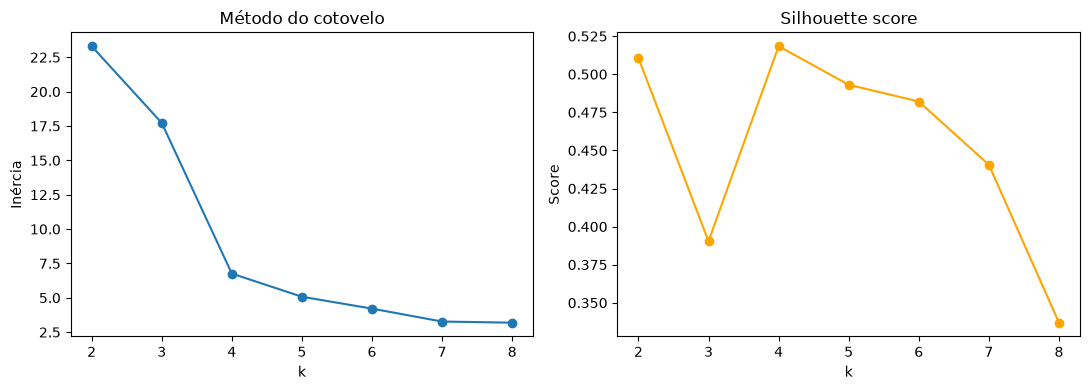

In [4]:
valores_k = range(2, min(8, len(df_cluster) - 1) + 1)
inercias = []
silhouettes = []

for k in valores_k:
    modelo = KMeans(n_clusters=k, random_state=42, n_init="auto").fit(X)
    inercias.append(modelo.inertia_)
    silhouettes.append(silhouette_score(X, modelo.labels_))

fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
eixos[0].plot(list(valores_k), inercias, marker="o")
eixos[0].set_title("Método do cotovelo")
eixos[0].set_xlabel("k")
eixos[0].set_ylabel("Inércia")

eixos[1].plot(list(valores_k), silhouettes, marker="o", color="orange")
eixos[1].set_title("Silhouette score")
eixos[1].set_xlabel("k")
eixos[1].set_ylabel("Score")

plt.tight_layout()
plt.show()

## 4. Aplicar K-Means

`K = 3` por padrão, pra comparar diretamente com as 3 classificações do módulo 4 (Alta/Média/Baixa). Ajuste esse valor se os gráficos acima sugerirem outro k mais natural pros seus dados.

In [5]:
K = 3
modelo_final = KMeans(n_clusters=K, random_state=42, n_init="auto").fit(X)
df_cluster["cluster"] = modelo_final.labels_

colunas_exibidas = [
    "codigo_produto", "nome_produto", "custo_gerencial_composto",
    "giro_90d", "score_prioridade", "classificacao", "cluster",
]
df_cluster[colunas_exibidas].sort_values("cluster")

,codigo_produto,nome_produto,custo_gerencial_composto,giro_90d,score_prioridade,classificacao,cluster
0,AP-1001,Filtro de óleo motor 1.0/1.6,22.69,5.8902,0.3158,Prioridade Baixa,0
1,AP-1002,Pastilha de freio dianteira,82.67,5.4074,0.2281,Prioridade Baixa,0
3,AP-1004,Correia dentada,50.02,5.1616,0.4035,Prioridade Média,0
4,AP-1005,Vela de ignição,11.21,6.0833,0.2807,Prioridade Baixa,0
7,AP-1008,Filtro de ar do motor,24.88,5.2484,0.3333,Prioridade Baixa,0
11,AP-1012,Óleo lubrificante 5W30 sintético (litro),26.00,6.1799,0.3860,Prioridade Média,0
15,AP-1016,Palheta limpador de para-brisa,14.83,4.6959,0.4035,Prioridade Média,0
5,AP-1006,Bomba de combustível elétrica,283.89,0.0000,0.6754,Prioridade Alta,1
10,AP-1011,Bateria automotiva 60Ah,348.04,3.7939,0.5965,Prioridade Média,1
6,AP-1007,Kit embreagem completo,460.88,1.1587,0.6667,Prioridade Média,1


## 5. Visualizar: K-Means vs classificação por regra (módulo 4)

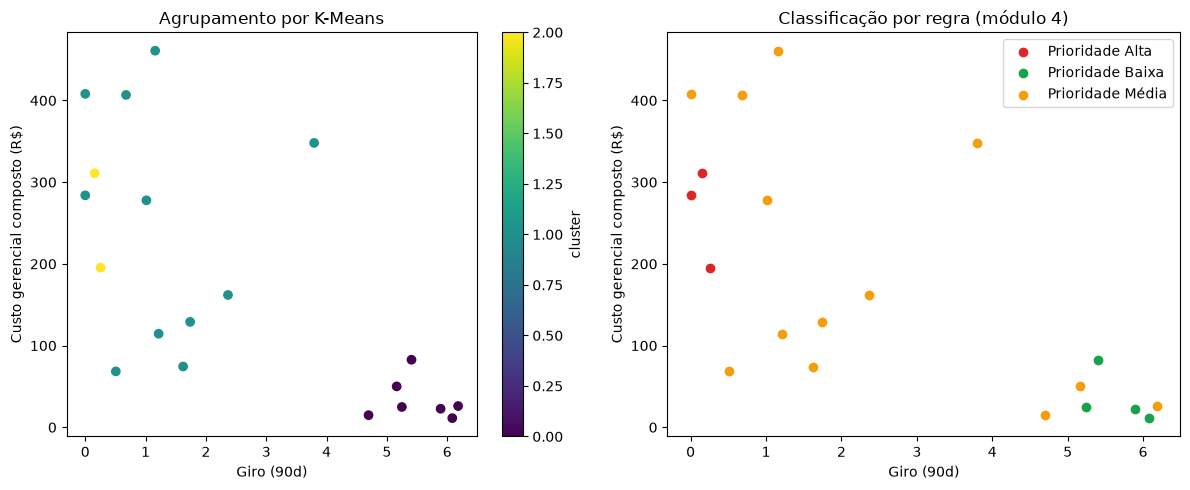

In [6]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 5))

dispersao = eixos[0].scatter(
    df_cluster["giro_90d"], df_cluster["custo_gerencial_composto"],
    c=df_cluster["cluster"], cmap="viridis",
)
eixos[0].set_title("Agrupamento por K-Means")
eixos[0].set_xlabel("Giro (90d)")
eixos[0].set_ylabel("Custo gerencial composto (R$)")
plt.colorbar(dispersao, ax=eixos[0], label="cluster")

cores_classificacao = {
    "Prioridade Alta": "#dc2626",
    "Prioridade Média": "#f59e0b",
    "Prioridade Baixa": "#16a34a",
}
for classificacao, grupo in df_cluster.groupby("classificacao"):
    eixos[1].scatter(
        grupo["giro_90d"], grupo["custo_gerencial_composto"],
        label=classificacao, color=cores_classificacao.get(classificacao),
    )
eixos[1].set_title("Classificação por regra (módulo 4)")
eixos[1].set_xlabel("Giro (90d)")
eixos[1].set_ylabel("Custo gerencial composto (R$)")
eixos[1].legend()

plt.tight_layout()
plt.show()

## 6. Interpretar os clusters

Média das features por cluster — usado pra dar um "nome" a cada grupo (ex.: cluster de custo alto e giro baixo = candidato a prioridade alta).

In [7]:
resumo_clusters = df_cluster.groupby("cluster")[FEATURES].mean().round(2)
resumo_clusters["quantidade_produtos"] = df_cluster.groupby("cluster").size()
resumo_clusters

,custo_gerencial_composto,giro_90d,score_prioridade,quantidade_produtos
cluster,,,,
0,33.19,5.52,0.34,7
1,248.51,1.28,0.54,11
2,253.10,0.20,0.84,2


## 7. O K-Means concorda com a classificação por regra?

In [8]:
pd.crosstab(df_cluster["cluster"], df_cluster["classificacao"])

classificacao,Prioridade Alta,Prioridade Baixa,Prioridade Média
cluster,,,
0,0,4,3
1,1,0,10
2,2,0,0


## Conclusão

Compare a tabela cruzada acima com o resumo por cluster:

- Se um cluster concentra a maioria numa única classificação → o K-Means **reforça** a regra atual do módulo 4.
- Se um cluster mistura classificações diferentes (ex.: metade "Alta", metade "Média") → pode indicar que o `score_prioridade` atual não captura bem esse padrão, e vale revisar os pesos das 3 dimensões (custo, giro, nível de estoque) ou considerar essa informação no cálculo do desconto máximo (módulo 5).